# Phase 1: Enhancement (charvi, LIVER, patient 1)

The goal of this notebook is to make my liver easier to segment in Phase 2. I went through the steps in the lecture order, and for each one I compared two methods.

| Step | My methods | Lecture |
|---|---|---|
| Windowing | abdomen window, level 40 / width 400 | Chapter 2.2 |
| Spatial filter | anisotropic diffusion (edge-preserving) vs Gaussian blur | Chapter 3 (anisotropic diffusion is an extension) |
| Contrast | CLAHE vs histogram equalisation | Chapter 2.2 (CLAHE is an extension) |
| Frequency | 2D DFT spectrum + homomorphic filter | Chapter 4 (homomorphic is an extension) |
| Validation | PSNR + CNR | |

## Step 0: Setup

Imports, my folders, and a loader for one slice (raw CT in HU, liver mask, tumour mask).

In [1]:
import os
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import structural_similarity as ssim

NAME = "charvi"
SLICES = "../data/slices/" + NAME
OUT = "outputs_charvi"                         # phase1/outputs_charvi
FIGS = "../report/figures/charvi"
os.makedirs(OUT + "/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

# list all the CT slices of this member
files = sorted(glob.glob(SLICES + "/*_ct.npy"))
print(len(files), "slices found")


def load(ct_path):
    # load one slice: raw CT (HU) + liver mask + tumour mask (True/False)
    base = ct_path.replace("_ct.npy", "")
    ct = np.load(ct_path)
    liver_mask = cv2.imread(base + "_liver.png", 0) > 0
    tumour_mask = cv2.imread(base + "_tumour.png", 0) > 0
    return ct, liver_mask, tumour_mask

18 slices found


## Step 1: Load the image

For the figures I use the slice with the biggest liver. First I show the raw CT and its HU histogram.

In [2]:
# Step 1: load the image -- the slice with the biggest liver is used for the figures
example = files[0]
biggest = -1
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    if liver_mask.sum() > biggest:
        biggest = liver_mask.sum()
        example = f

ct, liver_mask, tumour_mask = load(example)
print("example slice:", os.path.basename(example))

example slice: p1_s65_ct.npy


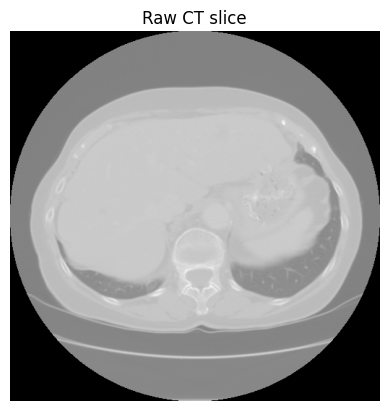

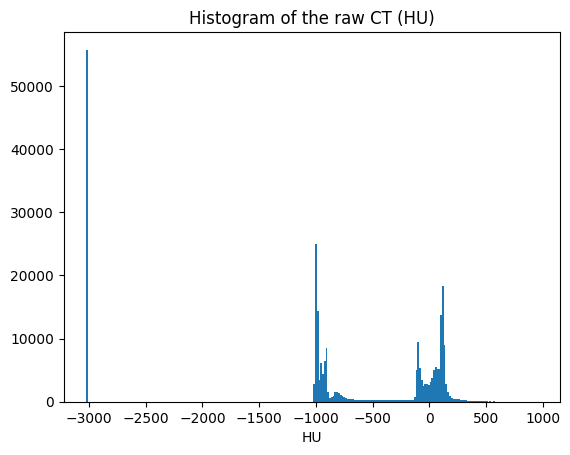

In [3]:
# show the raw CT (values are in HU, not 0-255)
plt.figure()
plt.imshow(ct, cmap='gray')
plt.title('Raw CT slice')
plt.axis('off')
plt.show()

# look at the histogram: most HU values are air (about -1000) or soft tissue (about 0 to 100)
plt.figure()
plt.hist(ct.ravel(), bins=256)
plt.title('Histogram of the raw CT (HU)')
plt.xlabel('HU')
plt.show()

## Step 2: Windowing (Chapter 2.2, point processing)

Windowing is the point operation s = T(r) from Chapter 2.2. I keep -160 to 240 HU (level 40, width 400) and stretch it to 0-255, and then I look at the new histogram.

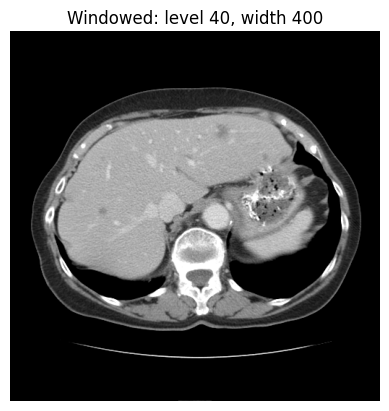

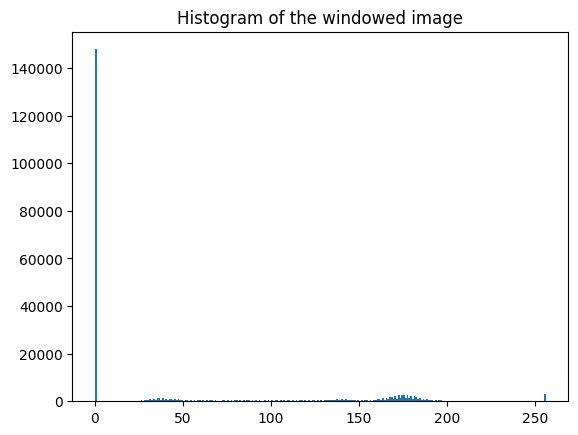

In [4]:
# ---- Step 2: windowing (Chapter 2.2, point processing s = T(r)) ----
def window(ct, level=40, width=400):
    # keep the soft-tissue HU range and stretch it to 0-255
    low = level - width / 2                   # -160 HU
    high = level + width / 2                  # 240 HU
    img = np.clip(ct, low, high)              # everything outside -> low or high
    img = (img - low) / (high - low) * 255    # stretch to 0-255
    return img.astype(np.uint8)

windowed_img = window(ct)

plt.figure()
plt.imshow(windowed_img, cmap='gray')
plt.title('Windowed: level 40, width 400')
plt.axis('off')
plt.show()

# histogram after windowing: the soft tissue now uses the whole 0-255 range
plt.figure()
plt.hist(windowed_img.ravel(), bins=256, range=(0, 256))
plt.title('Histogram of the windowed image')
plt.show()

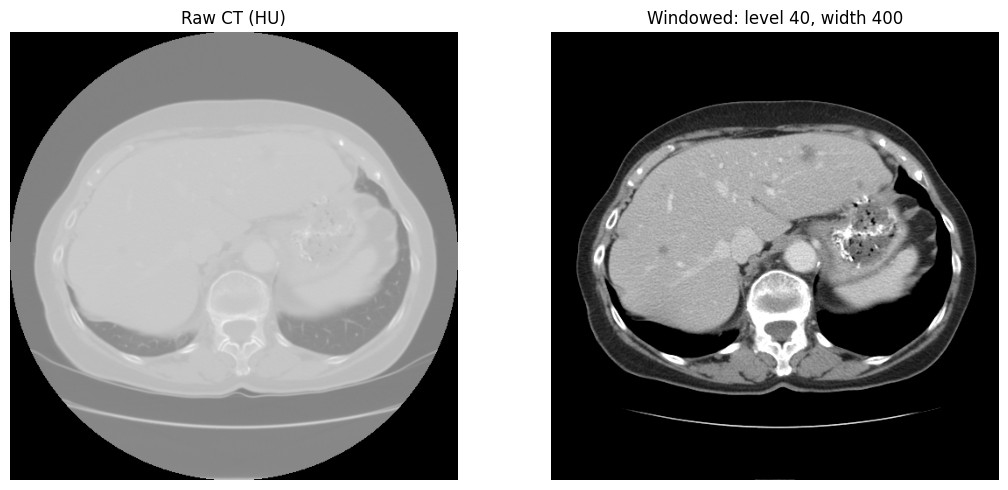

In [5]:
# save the comparison figure for the report
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(ct, cmap="gray")
ax[0].set_title("Raw CT (HU)")
ax[1].imshow(windowed_img, cmap="gray")
ax[1].set_title("Windowed: level 40, width 400")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_windowing.png", dpi=120)
plt.show()

## Step 3: Anisotropic diffusion vs Gaussian blur (Chapter 3)

The Gaussian blur is the Chapter 3 weighted average with a bell-shaped 5x5 mask (sigma 1). It averages everything, so edges get blurred too.

Anisotropic diffusion is an extension of the Chapter 3 smoothing filters and is not in the slides. The idea is that brightness repeatedly "flows" between neighbouring pixels, but the flow is blocked wherever the difference is large, which is an edge. I ran it for 15 iterations with kappa 30.

In [6]:
# ---- Step 3: spatial filtering ----
# anisotropic diffusion (Perona-Malik) is an extension of the Chapter 3 smoothing filters, it is not in the slides
def anisotropic_diffusion(img, iterations=15, kappa=30, gamma=0.15):
    # smooths flat areas, but stops at edges (big brightness jumps)
    I = img.astype(np.float64)
    for _ in range(iterations):
        # differences to the 4 neighbours (north, south, east, west)
        diffs = [np.roll(I, -1, 0) - I, np.roll(I, 1, 0) - I, np.roll(I, -1, 1) - I, np.roll(I, 1, 1) - I]
        # conduction: close to 1 for small differences (smooth), close to 0 at edges (keep)
        flow = 0
        for d in diffs:
            flow = flow + np.exp(-(d / kappa) ** 2) * d
        I = I + gamma * flow
    return np.clip(I, 0, 255).astype(np.uint8)

aniso_img = anisotropic_diffusion(windowed_img)

# Chapter 3: Gaussian blur = weighted average with a bell-shaped 5x5 mask, sigma 1
gauss_img = cv2.GaussianBlur(windowed_img, (5, 5), 1)

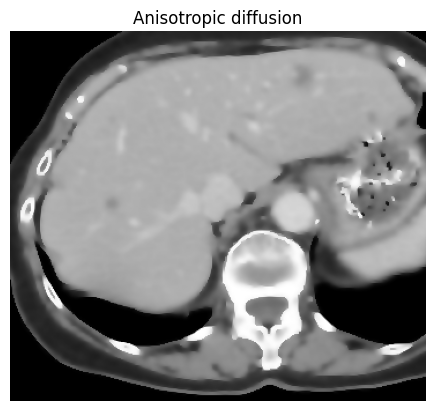

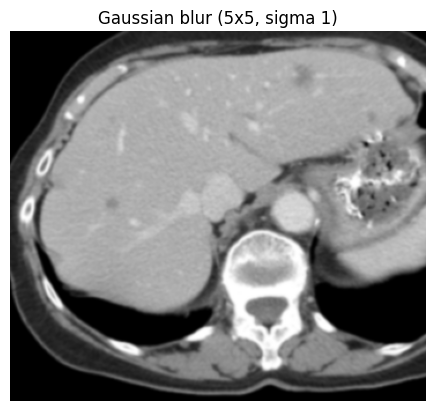

In [7]:
# zoom on the abdomen centre (rows 100-420, columns 40-400) so the liver is easier to see
plt.figure()
plt.imshow(aniso_img[100:420, 40:400], cmap='gray')
plt.title('Anisotropic diffusion')
plt.axis('off')
plt.show()

plt.figure()
plt.imshow(gauss_img[100:420, 40:400], cmap='gray')
plt.title('Gaussian blur (5x5, sigma 1)')
plt.axis('off')
plt.show()

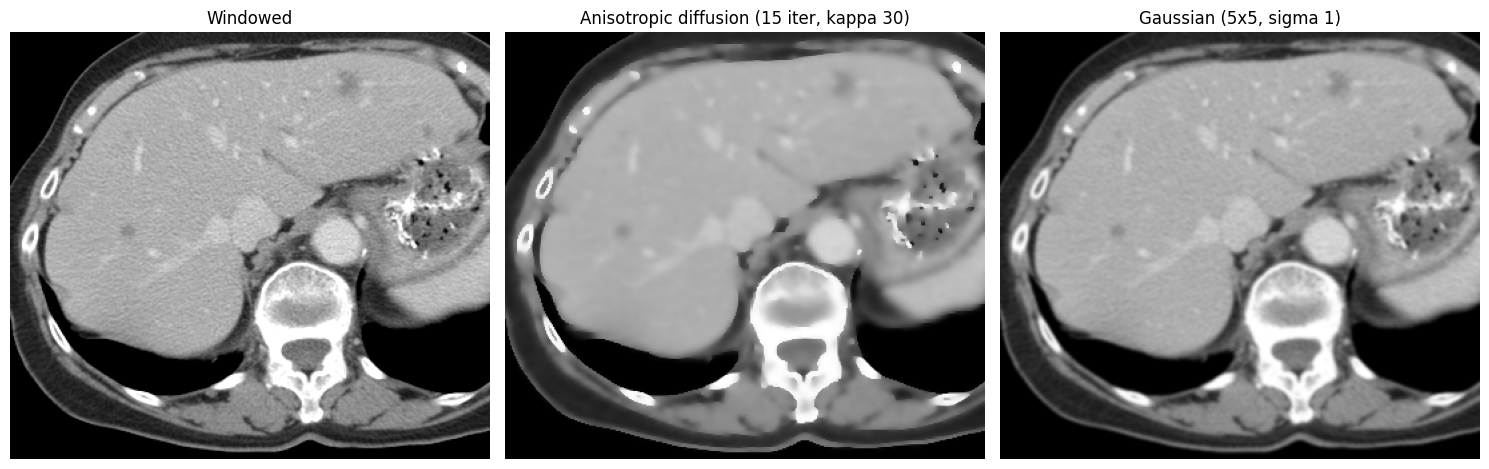

In [8]:
# save the comparison figure for the report
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(windowed_img[100:420, 40:400], cmap="gray")
ax[0].set_title("Windowed")
ax[1].imshow(aniso_img[100:420, 40:400], cmap="gray")
ax[1].set_title("Anisotropic diffusion (15 iter, kappa 30)")
ax[2].imshow(gauss_img[100:420, 40:400], cmap="gray")
ax[2].set_title("Gaussian (5x5, sigma 1)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_spatial_filters.png", dpi=120)
plt.show()

## Step 4: Histogram equalisation vs CLAHE (Chapter 2.2)

Histogram equalisation is in Chapter 2.2. CLAHE is its adaptive extension: it equalises 8x8 tiles separately and clips the histogram at 2.0, so noise is not over-boosted. Both are applied to the anisotropic diffusion output.

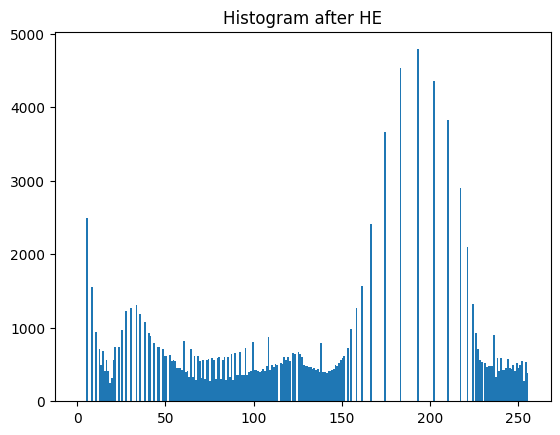

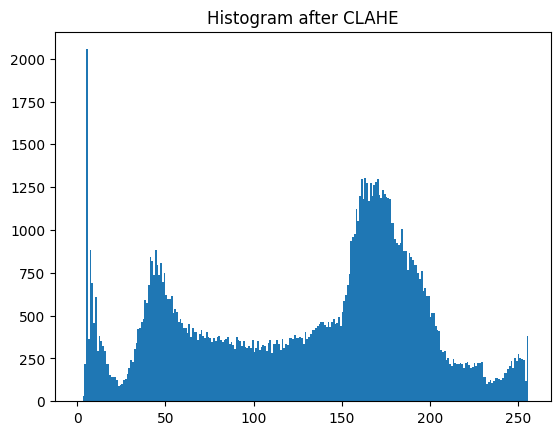

In [9]:
# ---- Step 4: contrast (Chapter 2.2 histogram equalisation; CLAHE is its adaptive extension) ----
he_img = cv2.equalizeHist(aniso_img)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(aniso_img)

# only look at pixels inside the body (ignore the black surround)
body = aniso_img > 0

# look at the histogram before and after equalisation
plt.figure()
plt.hist(he_img[body].ravel(), bins=256, range=(0, 256))
plt.title('Histogram after HE')
plt.show()

plt.figure()
plt.hist(clahe_img[body].ravel(), bins=256, range=(0, 256))
plt.title('Histogram after CLAHE')
plt.show()

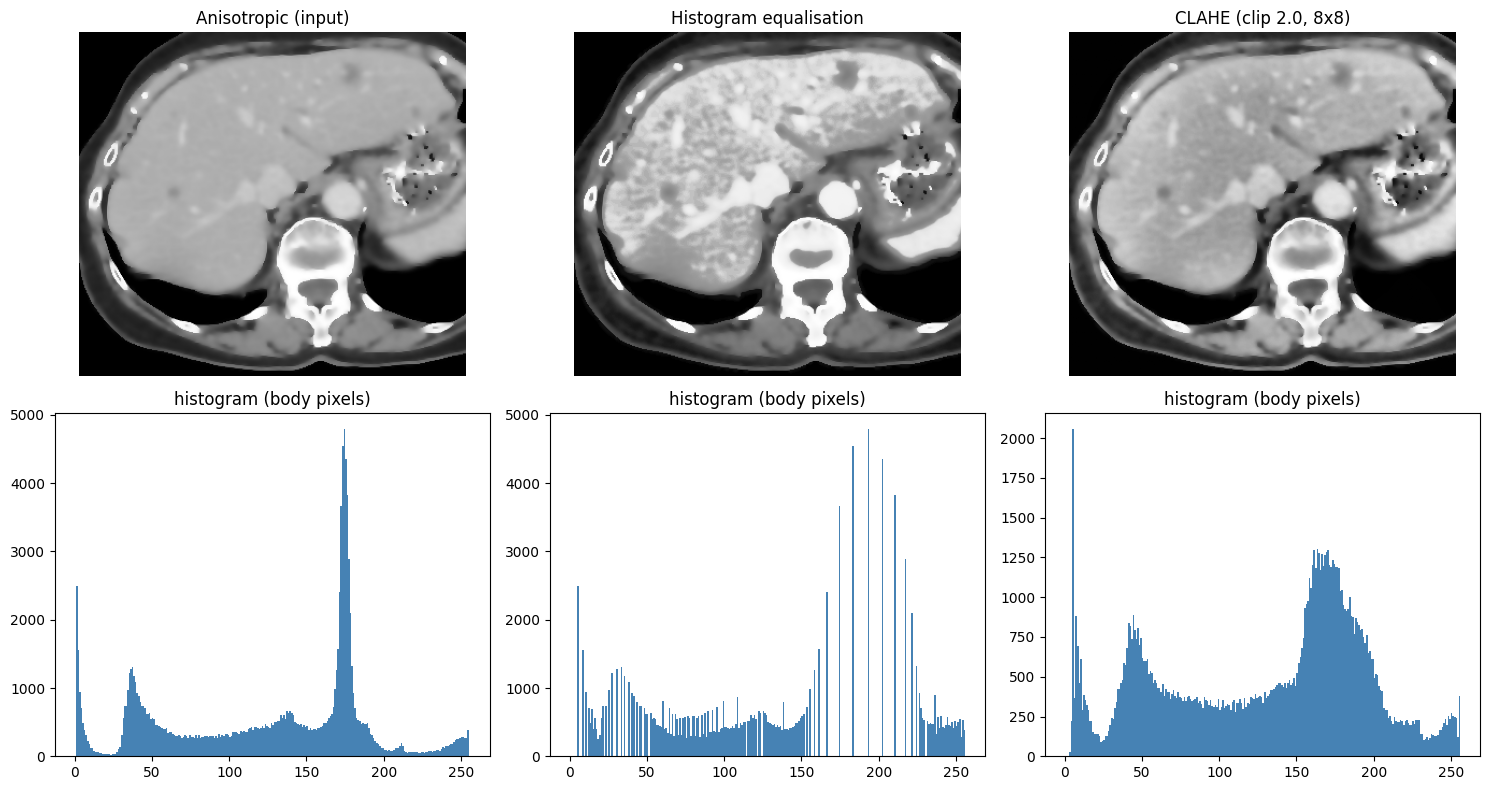

In [10]:
# save the comparison figure for the report (images on top, histograms below)
contrast_images = [aniso_img, he_img, clahe_img]
contrast_titles = ["Anisotropic (input)", "Histogram equalisation", "CLAHE (clip 2.0, 8x8)"]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j in range(3):
    img = contrast_images[j]
    ax[0, j].imshow(img[100:420, 40:400], cmap="gray")
    ax[0, j].set_title(contrast_titles[j])
    ax[0, j].axis("off")
    ax[1, j].hist(img[body].ravel(), bins=256, range=(0, 256), color="steelblue")
    ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_contrast.png", dpi=120)
plt.show()

## Step 5: Frequency domain, homomorphic filter (Chapter 4)

The homomorphic filter is an extension of the Chapter 4 Gaussian highpass filter. An image can be seen as lighting x reflectance. Taking the log turns that multiplication into an addition, so the slowly changing lighting (low frequencies) and the fine detail (high frequencies) can be treated separately. My filter turns the low frequencies down (x0.7) and the high frequencies up (x1.3).

I split the DFT into small cells: first the spectrum of the plain slice, then the log image and its spectrum, then H(u,v), then the multiplication and the inverse DFT.

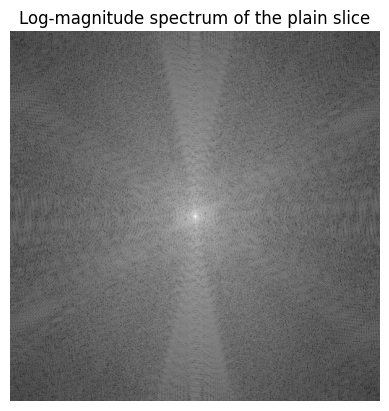

In [11]:
# ---- Step 5: frequency domain (Chapter 4) ----
# the homomorphic filter is an extension of the Chapter 4 Gaussian highpass filter, it is not in the slides

# spectrum of the plain slice (no log, no filter): 2D DFT, then move the low frequencies to the centre
F_plain = np.fft.fft2(windowed_img.astype(np.float64))
F_plain = np.fft.fftshift(F_plain)

plt.figure()
plt.imshow(np.log(1 + np.abs(F_plain)), cmap='gray')
plt.title('Log-magnitude spectrum of the plain slice')
plt.axis('off')
plt.show()

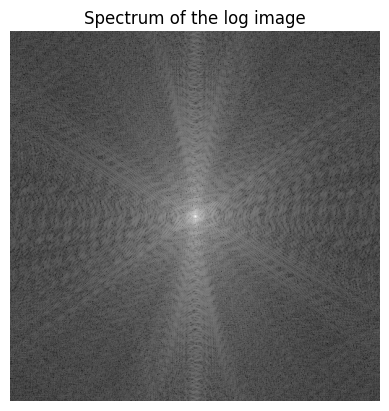

In [12]:
# take the log (lighting x reflectance -> lighting + reflectance), then the 2D DFT
log_img = np.log1p(windowed_img.astype(np.float64))
F = np.fft.fft2(log_img)
F = np.fft.fftshift(F)

plt.figure()
plt.imshow(np.log(1 + np.abs(F)), cmap='gray')
plt.title('Spectrum of the log image')
plt.axis('off')
plt.show()

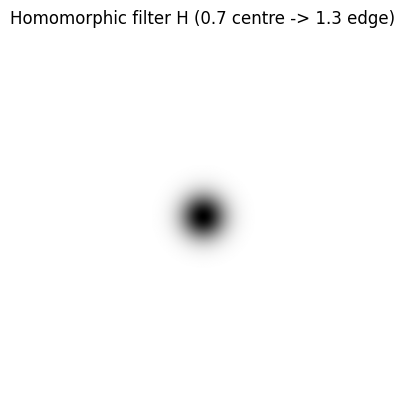

In [13]:
# build the homomorphic filter H(u,v): 0.7 at the centre (low frequencies) -> 1.3 far out (high frequencies)
D0 = 30
gamma_low = 0.7
gamma_high = 1.3
c = 1
rows, cols = windowed_img.shape
u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
D2 = u ** 2 + v ** 2                       # D(u,v)^2 = squared distance from the centre
H = (gamma_high - gamma_low) * (1 - np.exp(-c * D2 / D0 ** 2)) + gamma_low

plt.figure()
plt.imshow(H, cmap='gray')
plt.title('Homomorphic filter H (0.7 centre -> 1.3 edge)')
plt.axis('off')
plt.show()

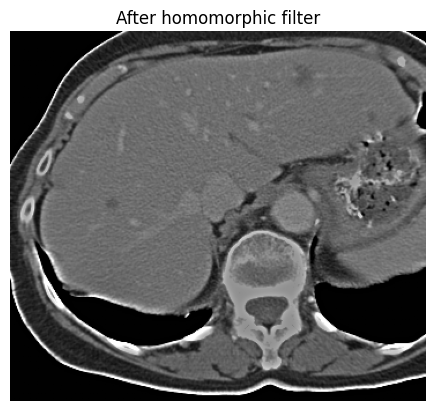

In [14]:
# multiply in the frequency domain, inverse DFT, then undo the log (exp)
G = F * H
out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(G))))

# robust rescale to 0-255: ignore the few extreme edge pixels (1st and 99th percentile)
percentiles = np.percentile(out, [1, 99])
low = percentiles[0]
high = percentiles[1]
out = np.clip((out - low) / (high - low + 1e-9), 0, 1) * 255
homo_img = out.astype(np.uint8)

plt.figure()
plt.imshow(homo_img[100:420, 40:400], cmap='gray')
plt.title('After homomorphic filter')
plt.axis('off')
plt.show()

In [15]:
# the same steps as a function, so it can be used on every slice below
def homomorphic(img, D0=30, gamma_low=0.7, gamma_high=1.3, c=1):
    F = np.fft.fftshift(np.fft.fft2(np.log1p(img.astype(np.float64))))
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D2 = u ** 2 + v ** 2
    H = (gamma_high - gamma_low) * (1 - np.exp(-c * D2 / D0 ** 2)) + gamma_low
    out = np.expm1(np.real(np.fft.ifft2(np.fft.ifftshift(F * H))))
    percentiles = np.percentile(out, [1, 99])
    low = percentiles[0]
    high = percentiles[1]
    out = np.clip((out - low) / (high - low + 1e-9), 0, 1) * 255
    return out.astype(np.uint8)

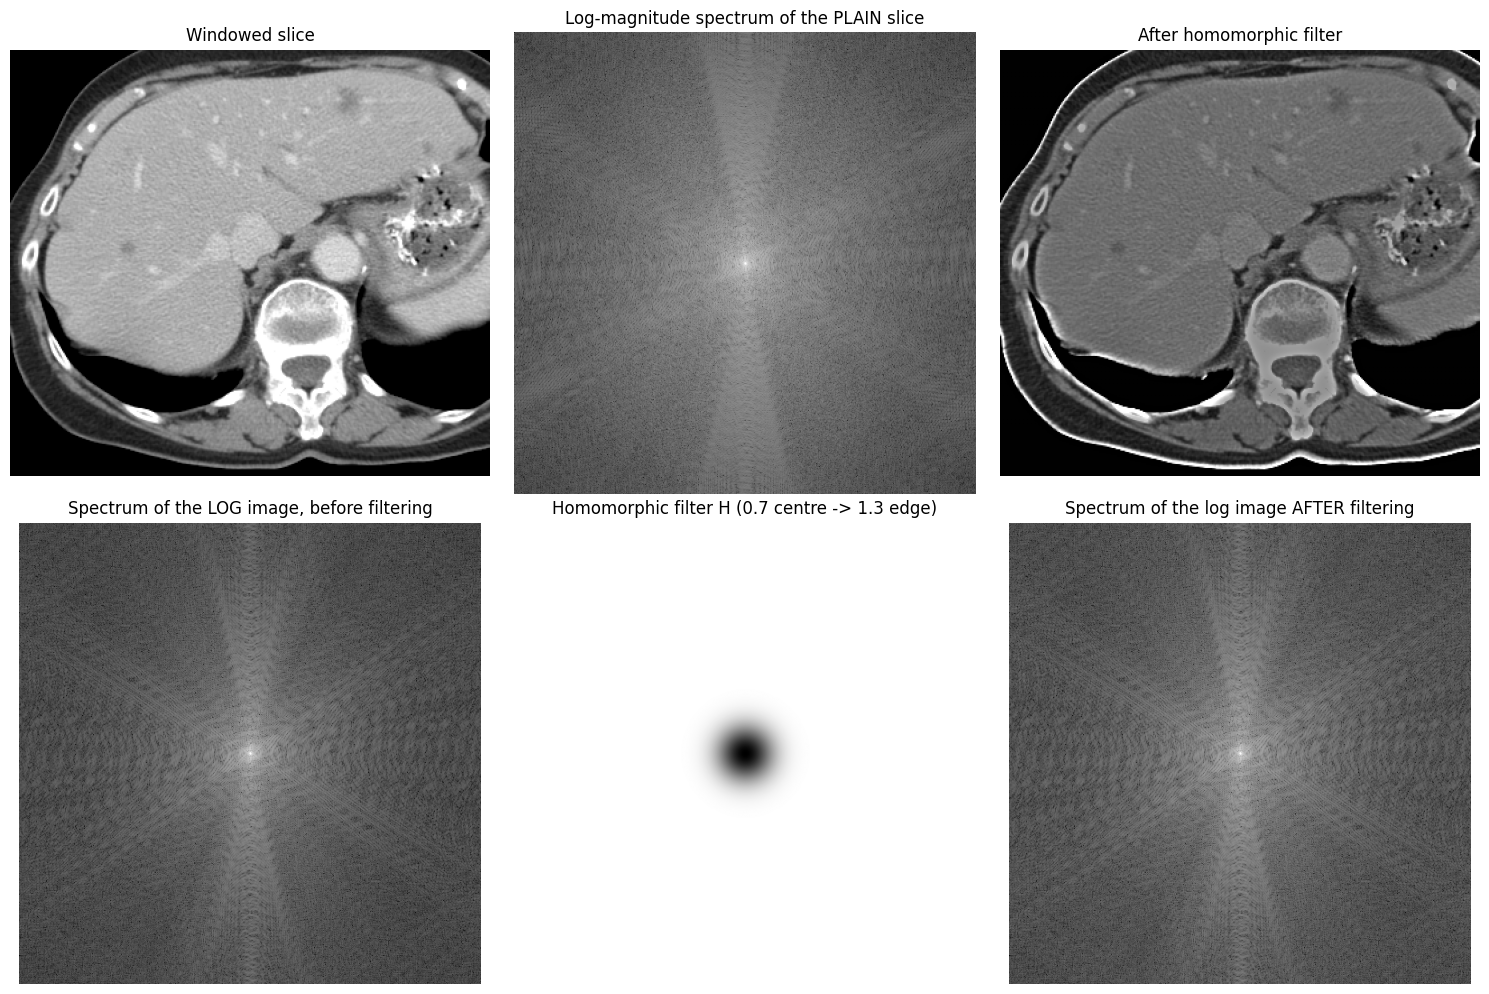

In [16]:
# save the comparison figure for the report
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(windowed_img[100:420, 40:400], cmap="gray")
ax[0, 0].set_title("Windowed slice")
ax[0, 1].imshow(np.log(1 + np.abs(F_plain)), cmap="gray")
ax[0, 1].set_title("Log-magnitude spectrum of the PLAIN slice")
ax[0, 2].imshow(homo_img[100:420, 40:400], cmap="gray")
ax[0, 2].set_title("After homomorphic filter")
ax[1, 0].imshow(np.log(1 + np.abs(F)), cmap="gray")
ax[1, 0].set_title("Spectrum of the LOG image, before filtering")
ax[1, 1].imshow(H, cmap="gray")
ax[1, 1].set_title("Homomorphic filter H (0.7 centre -> 1.3 edge)")
ax[1, 2].imshow(np.log(1 + np.abs(G)), cmap="gray")
ax[1, 2].set_title("Spectrum of the log image AFTER filtering")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.savefig(FIGS + "/" + NAME + "_p1_frequency.png", dpi=120)
plt.show()

## Step 6: Validation on all slices

Now I score every method on all slices. PSNR shows how much the method changed the windowed image. CNR shows how well the liver stands out from its surroundings and the tumour from the liver. The surroundings are a ring made by dilating the liver with a 25x25 structuring element (Chapter 8).

In [17]:
# ---- Step 6: validation on all slices (PSNR + CNR) ----
def psnr(ref, test):
    # how close the processed image stays to the original (dB). Higher = less changed
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10(255 ** 2 / mse)


def cnr(img, region, background):
    # how well a region stands out from its background. Higher = easier to see
    a = img[region].astype(np.float64)
    b = img[background].astype(np.float64)
    if len(a) == 0 or len(b) == 0:
        return np.nan
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var() + 1e-9)

In [18]:
# Chapter 8: 25x25 square structuring element for the dilation
square_se = cv2.getStructuringElement(cv2.MORPH_RECT, (25, 25))
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

metric_rows = []
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    slice_name = os.path.basename(f)[:-7]              # remove "_ct.npy"
    windowed_img = window(ct)

    # Chapter 8: dilate the liver, then remove the liver -> a ring of surrounding tissue
    dilated_liver = cv2.dilate(liver_mask.astype(np.uint8), square_se)
    ring = dilated_liver.astype(bool) & ~liver_mask

    # all the versions of this slice
    aniso_img = anisotropic_diffusion(windowed_img)
    versions = {}
    versions["windowed"] = windowed_img
    versions["anisotropic"] = aniso_img
    versions["gaussian"] = cv2.GaussianBlur(windowed_img, (5, 5), 1)
    versions["homomorphic"] = homomorphic(windowed_img)
    versions["aniso+HE"] = cv2.equalizeHist(aniso_img)
    versions["aniso+CLAHE"] = clahe.apply(aniso_img)

    for method in versions:
        img = versions[method]
        # the windowed image is the reference, so it has no PSNR
        if method == "windowed":
            psnr_value = np.nan
        else:
            psnr_value = psnr(windowed_img, img)
        row = {}
        row["slice"] = slice_name
        row["method"] = method
        row["PSNR"] = psnr_value
        row["CNR liver vs surroundings"] = cnr(img, liver_mask, ring)
        row["CNR tumour vs liver"] = cnr(img, tumour_mask, liver_mask & ~tumour_mask)
        metric_rows.append(row)

results = pd.DataFrame(metric_rows)
results.to_csv(OUT + "/phase1_metrics.csv", index=False)

# average of each method over all slices
summary = results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean()
print(summary.round(2))

              PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                            
windowed       NaN                       1.19                 1.56
anisotropic  31.88                       1.23                 1.77
gaussian     30.73                       1.24                 1.77
homomorphic  17.75                       0.70                 1.14
aniso+HE     24.78                       1.39                 1.75
aniso+CLAHE  26.27                       1.16                 1.92


## Step 7: Controlled noise test

PSNR against the windowed slice only tells me how much a filter changed the image, not whether it improved it. That is why we did a controlled test. The windowed slice is used as the clean reference. Gaussian noise with a known strength is added to the CT before windowing (sigma = 40 HU, so every member's window scales it like real CT noise; 40 HU is well above the CT's own noise), and then each filter has to remove it.

PSNR and SSIM (structural similarity, 1 = same structure) are measured against the clean slice on tissue pixels only, not on clipped black air or white bone. So here higher really means closer to the truth. Since the windowed slice already has some CT noise in it, this measures how well each filter removes the added noise.

In [19]:
NOISE_SIGMA_HU = 40      # same physical noise for every member, added in HU BEFORE windowing
noise_rng = np.random.default_rng(0)

metric_rows = []
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    slice_name = os.path.basename(f)[:-7]
    clean_img = window(ct)

    # add Gaussian noise in HU, then window (the window scales the noise like real CT noise)
    noise = noise_rng.normal(0, NOISE_SIGMA_HU, ct.shape)
    noisy_img = window(ct + noise)

    # score only tissue that is not clipped in the clean slice: in black air / white bone the noise
    # can only go one way and is clipped away, which would reward filters (e.g. median) just for
    # restoring flat black or white areas
    tissue = (clean_img > 0) & (clean_img < 255)

    filtered = {}
    filtered["noisy (no filter)"] = noisy_img
    filtered["anisotropic"] = anisotropic_diffusion(noisy_img)
    filtered["gaussian"] = cv2.GaussianBlur(noisy_img, (5, 5), 1)
    filtered["homomorphic"] = homomorphic(noisy_img)

    for method in filtered:
        img = filtered[method]
        score, ssim_map = ssim(clean_img, img, data_range=255, full=True)
        row = {}
        row["slice"] = slice_name
        row["method"] = method
        row["PSNR vs clean"] = psnr(clean_img[tissue], img[tissue])
        row["SSIM vs clean"] = ssim_map[tissue].mean()
        metric_rows.append(row)

noise_test = pd.DataFrame(metric_rows)
noise_test.to_csv(OUT + "/phase1_noise_test.csv", index=False)

print(f"Added Gaussian noise in HU, sigma = {NOISE_SIGMA_HU} HU (before windowing):")
noise_summary = noise_test.groupby("method", sort=False)[["PSNR vs clean", "SSIM vs clean"]].mean()
print(noise_summary.round(3))

Added Gaussian noise in HU, sigma = 40 HU (before windowing):
                   PSNR vs clean  SSIM vs clean
method                                         
noisy (no filter)         20.177          0.457
anisotropic               25.450          0.693
gaussian                  26.377          0.759
homomorphic               12.221          0.376


## Step 8: Final enhancement

In the end I chose windowing, then anisotropic diffusion, then CLAHE. Anisotropic diffusion keeps the liver edge sharp, which is good for region growing in Phase 2, and CLAHE raises the local contrast without the strong graininess of global HE. This cell applies the chain to every slice and saves it for Phase 2.

saved 18 enhanced slices to outputs_charvi/enhanced


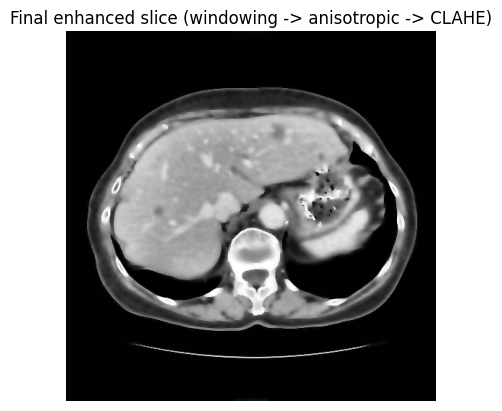

In [20]:
# apply the final chain to every slice and save it for Phase 2
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
for f in files:
    ct, liver_mask, tumour_mask = load(f)
    windowed_img = window(ct)                              # Step 2
    aniso_img = anisotropic_diffusion(windowed_img)        # Step 3
    enhanced_img = clahe.apply(aniso_img)                  # Step 4
    out_name = os.path.basename(f).replace("_ct.npy", "_enh.png")
    cv2.imwrite(OUT + "/enhanced/" + out_name, enhanced_img)
print("saved", len(files), "enhanced slices to", OUT + "/enhanced")

# show one final enhanced slice
example_name = os.path.basename(example).replace("_ct.npy", "_enh.png")
enhanced_example = cv2.imread(OUT + "/enhanced/" + example_name, 0)
plt.figure()
plt.imshow(enhanced_example, cmap='gray')
plt.title('Final enhanced slice (windowing -> anisotropic -> CLAHE)')
plt.axis('off')
plt.show()